# Сократился ли разрыв в продолжительности жизни между странами?

Продвинутый трек · социально-экономическая тема

**Вопрос исследования.** Насколько различалась ожидаемая продолжительность жизни в 2000 и 2019 годах между странами и территориями с более низким и более высоким ВВП на душу населения в начале периода? Сохраняется ли вывод, если исключить 5% самых богатых по этому показателю?

Сопоставимые национальные показатели позволяют оценить сближение групп. Состав групп фиксируется по ВВП на душу населения в 2000 году. Иначе изменение медианы могло бы отражать переход стран из одной группы в другую. Беру два среза с интервалом в 19 лет. 2019 год выбран как последний полный год до пандемии COVID-19.

Для повторного запуска нужны Python, pandas и Matplotlib. Положите два CSV в папку `data/` рядом с `project.ipynb` и выполните **Restart Kernel → Run All**. Ссылки на файлы даны ниже. Ноутбук читает локальные файлы и автоматически создаёт `results.txt`.

In [1]:
from math import ceil, isclose, nan
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd

DATA_DIR = Path("data")
GDP_FILE = DATA_DIR / "ddf--datapoints--gdp_pcap--by--country--time.csv"
LIFE_FILE = DATA_DIR / "ddf--datapoints--lex--by--country--time.csv"
YEARS = (2000, 2019)
LOWER = "Нижняя половина"
UPPER = "Верхняя половина"
GROUPS = (LOWER, UPPER)
TRIM_SHARE = 0.05
LIFE_THRESHOLD = 70
print(f"Годы сравнения — {YEARS[0]} и {YEARS[1]}. Порог продолжительности жизни — "
      f"{LIFE_THRESHOLD} лет. Для проверки исключаем верхние {TRIM_SHARE:.0%} по ВВП на человека.")

Годы сравнения — 2000 и 2019. Порог продолжительности жизни — 70 лет. Для проверки исключаем верхние 5% по ВВП на человека.


## 1. Данные

Установлены два анализируемых года, порог 70 лет для одного из показателей и доля для проверки чувствительности. Исходные таблицы **Gapminder Fast Track** скачаны **18 ноября 2026 года**. Ссылки указывают на зафиксированную версию репозитория. Обе таблицы хранятся в исходном виде. Одна строка — один показатель для страны или территории (`country`) в определённом году (`time`).

- **ВВП на душу населения** (`gdp_pcap`) измерен в постоянных международных долларах 2021 года по паритету покупательной способности (ППС). Показатель описывает выпуск экономики в пересчёте на человека. [CSV ВВП](https://raw.githubusercontent.com/open-numbers/ddf--gapminder--fasttrack/1f82fd693b2cf3cdba4e55c1a3770350d01b6c30/countries_etc_datapoints/ddf--datapoints--gdp_pcap--by--country--time.csv)
- **Ожидаемая продолжительность жизни при рождении** (`lex`) измерена в годах. Она показывает, сколько в среднем прожил бы новорождённый при сохранении возрастных коэффициентов смертности этого года. [CSV продолжительности жизни](https://raw.githubusercontent.com/open-numbers/ddf--gapminder--fasttrack/1f82fd693b2cf3cdba4e55c1a3770350d01b6c30/countries_etc_datapoints/ddf--datapoints--lex--by--country--time.csv) · [Определения показателей](https://github.com/open-numbers/ddf--gapminder--fasttrack/blob/1f82fd693b2cf3cdba4e55c1a3770350d01b6c30/ddf--concepts.csv)

Функция `load_indicator()` читает CSV по относительному пути. Значения сначала читаются как строки, чтобы при очистке можно было отделить пустые поля от некорректного текста. Если файл отсутствует, пуст или повреждён, функция выводит причину и возвращает пустую таблицу с ожидаемыми столбцами.

In [2]:
def load_indicator(path, value_column):
    columns = ["country", "time", value_column]
    empty = pd.DataFrame(columns=columns, dtype="string")
    try:
        table = pd.read_csv(path, dtype="string", encoding="utf-8")
    except (OSError, UnicodeError, pd.errors.ParserError, pd.errors.EmptyDataError) as error:
        print(f"Не удалось прочитать {path}. Причина: {error}")
        return empty

    missing_columns = [column for column in columns if column not in table.columns]
    if missing_columns:
        print(f"В {path.name} отсутствуют столбцы {', '.join(missing_columns)}.")
        return empty

    print(f"{path.name} → {len(table):,} строк")
    return table[columns]


raw_gdp = load_indicator(GDP_FILE, "gdp_pcap")
raw_life = load_indicator(LIFE_FILE, "lex")
print(f"Всего прочитано строк: {len(raw_gdp) + len(raw_life):,}")

ddf--datapoints--gdp_pcap--by--country--time.csv → 58,695 строк
ddf--datapoints--lex--by--country--time.csv → 57,335 строк
Всего прочитано строк: 116,030


В таблице ВВП **58 695 строк**, в таблице продолжительности жизни **57 335 строк**. В сумме получено **116 030 строк**. Файлы содержат длинные ряды по годам, поэтому перед сравнением нужно проверить числа и ключи, а затем выделить 2000 и 2019 годы.

## 2. Очистка и проверка качества

`clean_indicator()` удаляет пробелы по краям и подсчитывает строки с пустыми полями. Затем преобразует год и показатель в числа. Допустимый ключ содержит трёхбуквенный код и целый год в диапазоне 1800–2100, который охватывает исходные файлы. ВВП и продолжительность жизни должны быть конечными положительными числами. Для продолжительности жизни дополнительно задана верхняя граница 125 лет как проверка явно ошибочных записей.

Для совпадающих строк с одним ключом оставляется один экземпляр. Если значения для одного ключа различаются, отбрасываются все конфликтующие значения после удаления точных повторов. Это исключает произвольный выбор значения и раздувание числа записей при объединении. В отчёте каждая удалённая строка учитывается один раз.

In [3]:
def clean_indicator(raw, value_column, upper_limit=None):
    text = raw[["country", "time", value_column]].apply(lambda column: column.str.strip())
    text = text.replace("", pd.NA)
    missing = text.isna().any(axis=1)
    year = pd.to_numeric(text["time"], errors="coerce")
    value = pd.to_numeric(text[value_column], errors="coerce")
    valid_year_range = year.between(1800, 2100)
    valid_year = valid_year_range & year.where(valid_year_range).mod(1).eq(0)
    valid_key = text["country"].str.fullmatch(r"[a-z]{3}") & valid_year
    valid_value = value.gt(0) & value.lt(float("inf"))
    if upper_limit is not None:
        valid_value &= value.le(upper_limit)
    valid = (valid_key & valid_value).fillna(False)
    invalid = ~missing & ~valid

    keep = ~missing & valid
    cleaned = pd.DataFrame({
        "country": text.loc[keep, "country"],
        "year": year.loc[keep].astype("int64"),
        "value": value.loc[keep].astype("float64"),
    })
    repeated = cleaned.duplicated(keep="first")
    unique_rows = cleaned.loc[~repeated]
    conflicts = unique_rows.duplicated(subset=["country", "year"], keep=False)
    result = unique_rows.loc[~conflicts].reset_index(drop=True)
    audit = {
        "Прочитано строк": len(raw),
        "Строк с пропусками": int(missing.sum()),
        "Строк с некорректными значениями": int(invalid.sum()),
        "Удалено точных повторов": int(repeated.sum()),
        "Удалено конфликтующих строк": int(conflicts.sum()),
        "Осталось строк": len(result),
    }
    return result, audit, text.loc[invalid]


gdp, gdp_audit, invalid_gdp = clean_indicator(raw_gdp, "gdp_pcap")
life, life_audit, invalid_life = clean_indicator(raw_life, "lex", upper_limit=125)
source_audit = pd.DataFrame([gdp_audit, life_audit], index=["ВВП", "Продолжительность жизни"])
display(source_audit.T)
if not invalid_life.empty:
    display(invalid_life.groupby(["country", "lex"])["time"].agg(["count", "min", "max"])
            .rename(columns={"count": "Строк", "min": "Первый год", "max": "Последний год"}))

,ВВП,Продолжительность жизни
Прочитано строк,58695,57335
Строк с пропусками,0,0
Строк с некорректными значениями,0,77
Удалено точных повторов,0,0
Удалено конфликтующих строк,0,0
Осталось строк,58695,57258


,,Строк,Первый год,Последний год
country,lex,,,
lie,0,77,2024,2100


В обоих CSV **0 строк с пропусками, 0 точных повторов и 0 конфликтующих строк**. В таблице продолжительности жизни найдено **77 некорректных нулевых значений** для Лихтенштейна (`lie`) за 2024–2100 годы. Это около **0,13%** строк этой таблицы. Эти записи исключены, и ни одна из них не относится к двум выбранным годам. У ВВП некорректных значений по заданным правилам нет.

## 3. Объединение и формирование групп

`make_panel()` сначала берёт 2000 и 2019 годы, затем объединяет таблицы **по коду страны и году**. Внешнее объединение (`outer`) помогает увидеть отсутствующие пары. Для сравнения оставляются страны и территории, у которых обе переменные есть в обоих годах. Такой набор называется сбалансированной панелью.

Функция `income_groups()` сортирует страны по ВВП на человека в базовом году, при равенстве использует порядок кодов. Первые `n // 2` попадают в нижнюю половину, остальные в верхнюю. Группа остаётся той же в 2019 году. Это относительные группы внутри этой выборки.

In [4]:
def income_groups(baseline):
    ranked = baseline.dropna(subset=["gdp"]).sort_values(["gdp", "country"])
    groups = pd.Series(UPPER, index=ranked["country"], dtype="string")
    groups.iloc[:len(groups) // 2] = LOWER
    return groups


def make_panel(gdp, life, years):
    gdp_dates = gdp.loc[gdp["year"].isin(years)].rename(columns={"value": "gdp"})
    life_dates = life.loc[life["year"].isin(years)].rename(columns={"value": "life"})
    joined = gdp_dates.merge(
        life_dates, on=["country", "year"], how="outer",
        indicator=True, validate="one_to_one",
    )
    paired = joined.loc[joined["_merge"].eq("both")].drop(columns="_merge")
    number_of_years = paired.groupby("country")["year"].transform("nunique")
    panel = paired.loc[number_of_years.eq(len(years))].copy()

    baseline_groups = income_groups(panel.loc[panel["year"].eq(years[0])])
    panel["group"] = panel["country"].map(baseline_groups)
    return panel, joined


panel, joined = make_panel(gdp, life, YEARS)
coverage = (
    pd.crosstab(joined["year"], joined["_merge"])
    .reindex(index=YEARS, columns=["both", "left_only", "right_only"], fill_value=0)
    .rename(columns={"both": "Оба показателя", "left_only": "Только ВВП",
                     "right_only": "Только продолжительность жизни"})
    .rename_axis(index="Год", columns=None)
)
display(coverage)
unpaired = joined.loc[joined["_merge"].ne("both"), ["country", "year", "gdp", "life"]]
if not unpaired.empty:
    display(unpaired.reset_index(drop=True))
seen = joined["country"].nunique()
retained = panel["country"].nunique()
print(f"Стран и территорий хотя бы с одним показателем: {seen}. "
      f"В полной панели: {retained} ({len(panel)} строк).")
if seen:
    print(f"Исключено из-за неполных данных: {seen - retained} из {seen} "
          f"({(seen - retained) / seen:.2%}).")

,Оба показателя,Только ВВП,Только продолжительность жизни
Год,,,
2000,195,0,1
2019,194,1,1


,country,year,gdp,life
0,hkg,2019,65388.33087,NaN
1,lie,2000,NaN,78.6
2,lie,2019,NaN,83.4


Стран и территорий хотя бы с одним показателем: 196. В полной панели: 194 (388 строк).
Исключено из-за неполных данных: 2 из 196 (1.02%).


У Лихтенштейна (`lie`) нет ВВП в обоих срезах. У Гонконга (`hkg`) есть оба показателя в 2000 году, а в 2019 году отсутствует значение продолжительности жизни. Поэтому из **196** стран и территорий, представленных хотя бы в одном из целевых срезов, в итоговой панели остаются **194**. Это **388 наблюдений** за два года. Из-за неполного покрытия потеряно около **1%** стран и территорий. Расчёт на фиксированной панели позволяет сравнивать одни и те же страны, при этом вывод относится к 194 выбранным участникам.

## 4. Показатели двух групп

`group_metrics()` считает объём, пропуски и характеристики уровней ВВП и продолжительности жизни. Межквартильный размах (IQR) — разность 75-го и 25-го процентилей. Он показывает ширину центральной половины распределения. Доля с продолжительностью жизни от 70 лет считается от числа доступных значений. При пустой группе доля неопределённа и отображается как пропуск.

`summarize()` применяет одни и те же расчёты к каждой паре «год и группа». Так сравнение можно повторить на сокращённой панели.

In [5]:
METRIC_LABELS = {
    "n": "Наблюдений",
    "gdp_missing": "Пропусков ВВП",
    "life_missing": "Пропусков продолжительности жизни",
    "gdp_mean": "Средний ВВП на человека, межд. долл.",
    "gdp_median": "Медианный ВВП на человека, межд. долл.",
    "life_mean": "Средняя продолжительность жизни, лет",
    "life_median": "Медианная продолжительность жизни, лет",
    "life_min": "Минимальная продолжительность жизни, лет",
    "life_max": "Максимальная продолжительность жизни, лет",
    "life_iqr": "IQR продолжительности жизни, лет",
    "life_share": f"Доля с продолжительностью жизни ≥ {LIFE_THRESHOLD} лет, %",
}


def group_metrics(rows, threshold=LIFE_THRESHOLD):
    life = rows["life"].dropna()
    gdp = rows["gdp"].dropna()
    share = 100 * life.ge(threshold).sum() / len(life) if len(life) else nan
    return {
        "n": len(rows),
        "gdp_missing": len(rows) - len(gdp),
        "life_missing": len(rows) - len(life),
        "gdp_mean": gdp.mean(),
        "gdp_median": gdp.median(),
        "life_mean": life.mean(),
        "life_median": life.median(),
        "life_min": life.min(),
        "life_max": life.max(),
        "life_iqr": life.quantile(0.75) - life.quantile(0.25),
        "life_share": share,
    }


def summarize(panel, years):
    metrics = []
    for year in years:
        for group in GROUPS:
            rows = panel.loc[panel["year"].eq(year) & panel["group"].eq(group)]
            metrics.append({"Год": year, "Группа": group, **group_metrics(rows)})
    return pd.DataFrame(metrics).set_index(["Год", "Группа"])


full_stats = summarize(panel, YEARS)
can_compare = full_stats["n"].gt(0).all()
display(full_stats.T.rename(index=METRIC_LABELS).round(2))

Год                                                    2000                   \
Группа                                      Нижняя половина Верхняя половина   
Наблюдений                                            97.00            97.00   
Пропусков ВВП                                          0.00             0.00   
Пропусков продолжительности жизни                      0.00             0.00   
Средний ВВП на человека, межд. долл.                3941.33         32487.24   
Медианный ВВП на человека, межд. долл.              3621.83         20439.64   
Средняя продолжительность жизни, лет                  61.53            73.82   
Медианная продолжительность жизни, лет                63.30            74.10   
Минимальная продолжительность жизни, лет              43.10            48.80   
Максимальная продолжительность жизни, лет             77.20            81.30   
IQR продолжительности жизни, лет                      14.90             6.10   
Доля с продолжительностью жизни ≥ 70 лет, %           21.65            87.63   

Год                                                    2019                   
Группа                                      Нижняя половина Верхняя половина  
Наблюдений                                            97.00            97.00  
Пропусков ВВП                                          0.00             0.00  
Пропусков продолжительности жизни                      0.00             0.00  
Средний ВВП на человека, межд. долл.                6921.39         43883.38  
Медианный ВВП на человека, межд. долл.              5702.08         35123.49  
Средняя продолжительность жизни, лет                  68.27            77.82  
Медианная продолжительность жизни, лет                68.70            77.70  
Минимальная продолжительность жизни, лет              53.80            62.10  
Максимальная продолжительность жизни, лет             80.10            86.30  
IQR продолжительности жизни, лет                       9.60             6.50  
Доля с продолжительностью жизни ≥ 70 лет, %           43.30            94.85

В каждом году обе половины включают по **97 наблюдений**, пропусков в панели нет. В нижней половине медиана выросла с **63,3** до **68,7 года**, а доля со значением от 70 лет — с **21,65%** до **43,30%**. В верхней половине медиана выросла с **74,1** до **77,7 года**, а доля от 70 лет — с **87,63%** до **94,85%**. Следующий шаг показывает, как менялось расстояние между группами.

## 5. Разница в годах и в процентах

Для каждой даты `compare_groups()` вычитает медиану нижней группы из медианы верхней. Относительная разница — эта разность, делённая на медиану нижней группы и умноженная на 100. Например, если медианы 60 и 75 лет, абсолютная разница равна 15 годам, а относительная — 25%. Дополнительно сравниваю разность средних. При нулевой или отсутствующей медиане знаменатель не позволяет вычислить процент.

In [6]:
GAP_LABELS = {
    "median_gap": "Разница медиан, лет",
    "relative_gap": "Верхняя медиана выше нижней на, %",
    "mean_gap": "Разница средних, лет",
}


def compare_groups(summary, years):
    comparisons = []
    for year in years:
        lower = summary.loc[(year, LOWER)]
        upper = summary.loc[(year, UPPER)]
        median_gap = upper["life_median"] - lower["life_median"]
        lower_median = lower["life_median"]
        relative_gap = 100 * median_gap / lower_median if lower_median > 0 else nan
        comparisons.append({
            "Год": year,
            "median_gap": median_gap,
            "relative_gap": relative_gap,
            "mean_gap": upper["life_mean"] - lower["life_mean"],
        })
    return pd.DataFrame(comparisons).set_index("Год")


full_gaps = compare_groups(full_stats, YEARS)
display(full_gaps.rename(columns=GAP_LABELS).round(2))

,"Разница медиан, лет","Верхняя медиана выше нижней на, %","Разница средних, лет"
Год,,,
2000,10.8,17.06,12.28
2019,9.0,13.10,9.55


Разрыв по медиане сократился с **10,8 до 9,0 года**, то есть на **1,8 года**. В 2000 году верхняя медиана была выше нижней на **17,06%**, в 2019 году — на **13,10%**. Разность средних также уменьшилась, с **12,28 до 9,55 года**. Знак изменения совпадает у средней и медианной оценок.

## 6. Как влияет неполнота данных?

В основном расчёте Гонконг выпал из обоих срезов, хотя его продолжительность жизни за 2000 год известна. Проверю, насколько это повлияло на результат. Формирую группы тем же способом по всем известным значениям ВВП на человека в 2000 году. Для каждого года включаю участника, если известны его группа и продолжительность жизни в этом году. Пропущенные значения не заполняю.

In [7]:
baseline_groups = income_groups(joined.loc[joined["year"].eq(YEARS[0])])
available = joined[["country", "year", "gdp", "life"]].copy()
available["group"] = available["country"].map(baseline_groups)
available = available.dropna(subset=["group", "life"])

available_stats = summarize(available, YEARS)
available_gaps = compare_groups(available_stats, YEARS)
coverage_check = available_stats["n"].unstack("Группа").reindex(columns=GROUPS).rename_axis(columns=None)
coverage_check["Разрыв при всех доступных наблюдениях, лет"] = available_gaps["median_gap"]
coverage_check["Разрыв в полной панели, лет"] = full_gaps["median_gap"]
display(coverage_check.round(2))
old_groups = panel.drop_duplicates("country").set_index("country")["group"]
changed = old_groups.ne(baseline_groups.reindex(old_groups.index)).sum()
print(f"Участников полной панели, перешедших в другую группу при этом расчёте: {changed}.")

,Нижняя половина,Верхняя половина,"Разрыв при всех доступных наблюдениях, лет","Разрыв в полной панели, лет"
Год,,,,
2000,97,98,10.85,10.8
2019,97,97,9.00,9.0


Участников полной панели, перешедших в другую группу при этом расчёте: 0.


В 2000 году в верхней группе стало **98** участников вместо 97. У всех **194** участников полной панели группа сохранилась. С учётом Гонконга разрыв в 2000 году равен **10,85 года** против **10,80** в основном расчёте. В 2019 году обе оценки равны **9,00 года**. Исключение известного наблюдения меняет начальную оценку на **0,05 года**. Для Лихтенштейна отсутствует исходный ВВП на человека, поэтому определить его группу этим способом нельзя.

## 7. Проверка чувствительности к высоким значениям ВВП на человека

Возвращаюсь к полной панели и исключаю участников с наибольшим ВВП **на душу населения в 2000 году**. Функция `drop_richest()` умножает число участников на 5% и округляет число исключаемых вверх до целого. Исключённые страны удаляются из обоих срезов. У оставшихся группа сохраняется. Так можно проверить, зависит ли разрыв от присутствия экономик с самыми высокими значениями ВВП на человека.

In [8]:
def drop_richest(panel, initial_year, fraction):
    ranked = panel.loc[panel["year"].eq(initial_year)].sort_values(["gdp", "country"])
    count = ceil(len(ranked) * fraction)
    excluded = ranked.tail(count)["country"].tolist()
    return panel.loc[~panel["country"].isin(excluded)].copy(), excluded


trimmed_panel, excluded_codes = drop_richest(panel, YEARS[0], TRIM_SHARE)
trimmed_stats = summarize(trimmed_panel, YEARS)
trimmed_gaps = compare_groups(trimmed_stats, YEARS)

print(f"Удалено стран и территорий: {len(excluded_codes)} ({len(panel) - len(trimmed_panel)} строк).")
if retained:
    print(f"Фактическая доля исключённых: {len(excluded_codes) / retained:.2%}.")
print("Коды:", ", ".join(excluded_codes) if excluded_codes else "—")
samples = {
    "Полная панель": (full_stats, full_gaps),
    "Без верхних 5%": (trimmed_stats, trimmed_gaps),
}
display(pd.concat({name: gap for name, (_, gap) in samples.items()}, names=["Вариант"])
        .rename(columns=GAP_LABELS).round(2))
display(trimmed_stats.T.rename(index=METRIC_LABELS).round(2))

Удалено стран и территорий: 10 (20 строк).
Фактическая доля исключённых: 5.15%.
Коды: kwt, sgp, che, nor, smr, qat, are, brn, lux, mco


Разница медиан, лет  Верхняя медиана выше нижней на, %  \
Вариант        Год                                                            
Полная панель  2000                 10.8                              17.06   
               2019                  9.0                              13.10   
Без верхних 5% 2000                 10.6                              16.75   
               2019                  8.7                              12.66   

                     Разница средних, лет  
Вариант        Год                         
Полная панель  2000                 12.28  
               2019                  9.55  
Без верхних 5% 2000                 11.92  
               2019                  9.05

Год                                                    2000                   \
Группа                                      Нижняя половина Верхняя половина   
Наблюдений                                            97.00            87.00   
Пропусков ВВП                                          0.00             0.00   
Пропусков продолжительности жизни                      0.00             0.00   
Средний ВВП на человека, межд. долл.                3941.33         25088.70   
Медианный ВВП на человека, межд. долл.              3621.83         18556.86   
Средняя продолжительность жизни, лет                  61.53            73.46   
Медианная продолжительность жизни, лет                63.30            73.90   
Минимальная продолжительность жизни, лет              43.10            48.80   
Максимальная продолжительность жизни, лет             77.20            81.30   
IQR продолжительности жизни, лет                      14.90             5.90   
Доля с продолжительностью жизни ≥ 70 лет, %           21.65            86.21   

Год                                                    2019                   
Группа                                      Нижняя половина Верхняя половина  
Наблюдений                                            97.00            87.00  
Пропусков ВВП                                          0.00             0.00  
Пропусков продолжительности жизни                      0.00             0.00  
Средний ВВП на человека, межд. долл.                6921.39         35406.86  
Медианный ВВП на человека, межд. долл.              5702.08         33202.35  
Средняя продолжительность жизни, лет                  68.27            77.31  
Медианная продолжительность жизни, лет                68.70            77.40  
Минимальная продолжительность жизни, лет              53.80            62.10  
Максимальная продолжительность жизни, лет             80.10            84.60  
IQR продолжительности жизни, лет                       9.60             6.60  
Доля с продолжительностью жизни ≥ 70 лет, %           43.30            94.25

Из полной панели исключены **10 из 194** участников (5,15%). Поэтому в каждом году остаются **97** наблюдений в нижней группе и **87** в верхней. Разрыв по медиане сокращается с **10,6 до 8,7 года**, то есть на **1,9 года**. Это близко к сокращению на 1,8 года в полной панели. Разница средних и здесь уменьшается. Графики показывают уровни и разрыв для двух выбранных дат.

### Как читать графики

Левый график показывает уровни медиан в полной панели. Правый сравнивает разницу медиан в полной и сокращённой панелях. Соединительные линии визуально сопоставляют два среза. Промежуточные годы в этом проекте не рассчитаны.

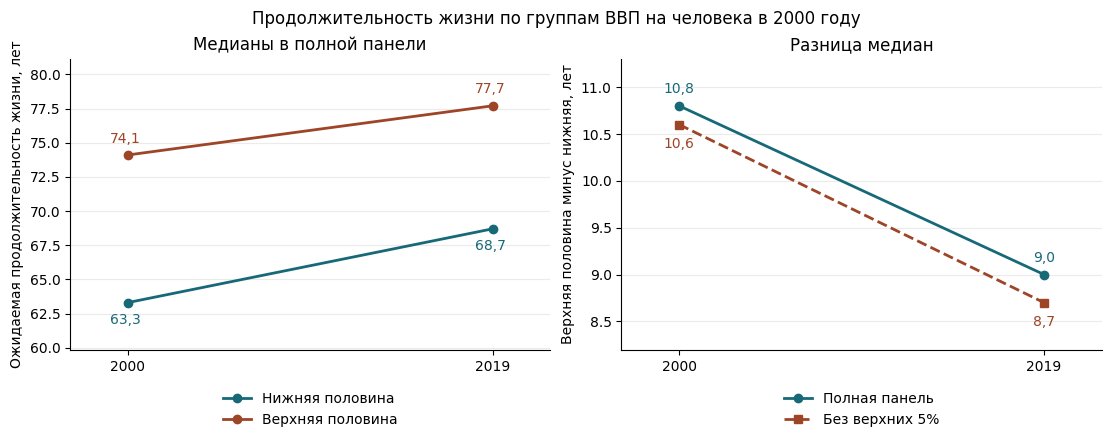

In [9]:
def plot_comparison(full_summary, variants, years):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
    colors = ["#176978", "#9e4427"]
    offsets = [(-13, -15), (-13, 9)]
    for group, color, offset in zip(GROUPS, colors, offsets):
        values = full_summary.xs(group, level="Группа")["life_median"]
        axes[0].plot(years, values, color=color, marker="o", linewidth=2, label=group)
        for year, value in values.items():
            axes[0].annotate(f"{value:.1f}".replace(".", ","), (year, value),
                             xytext=offset, textcoords="offset points", color=color)
    axes[0].set_title("Медианы в полной панели")
    axes[0].set_ylabel("Ожидаемая продолжительность жизни, лет")

    styles = [("-", "o"), ("--", "s")]
    for (name, (_, gaps)), color, style, dy in zip(variants.items(), colors, styles, [9, -17]):
        values = gaps["median_gap"]
        axes[1].plot(years, values, color=color, linestyle=style[0], marker=style[1],
                     linewidth=2, label=name)
        for year, value in values.items():
            axes[1].annotate(f"{value:.1f}".replace(".", ","), (year, value),
                             xytext=(0, dy), ha="center", textcoords="offset points", color=color)
    axes[1].set_title("Разница медиан")
    axes[1].set_ylabel("Верхняя половина минус нижняя, лет")

    for ax in axes:
        ax.set_xticks(years)
        ax.set_xlim(years[0] - 3, years[-1] + 3)
        ax.margins(y=0.24)
        ax.grid(axis="y", alpha=0.25)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), frameon=False)
    fig.suptitle("Продолжительность жизни по группам ВВП на человека в 2000 году")
    plt.show()


if not can_compare:
    print("Для графиков нужны наблюдения в обеих группах за каждый год.")
else:
    plot_comparison(full_stats, samples, YEARS)

На графиках видно, что медианы выросли в обеих группах, а в нижней рост между двумя срезами был больше. Две оценки разрыва близки по величине и обе уменьшаются. Прежде чем сохранять результаты, проверяю арифметику и правила отбора на примерах с известными ответами.

## 8. Проверки на маленьких примерах

`run_checks()` проверяет среднее, медиану, IQR и долю на пяти числах. Для 60, 65, 70, 75 и 80 среднее и медиана равны 70, IQR равен 10, а три из пяти значений достигли порога 70. Остальные проверки покрывают пустой ввод, одну строку, нулевой знаменатель, ошибки и дубликаты, объединение и очистку верхнего хвоста. Эти маленькие наборы используются только для проверок.

In [10]:
def run_checks():
    examples = pd.DataFrame({"gdp": [100, 200, 300, 400, 500], "life": [60, 65, 70, 75, 80]})
    metrics = group_metrics(examples, threshold=70)
    assert metrics["life_mean"] == metrics["life_median"] == 70
    assert metrics["life_iqr"] == 10 and metrics["life_share"] == 60
    assert metrics["life_min"] == 60 and metrics["life_max"] == 80

    with_gap = examples.iloc[:3].copy()
    with_gap["life"] = [60, 70, nan]
    metrics_with_gap = group_metrics(with_gap, threshold=70)
    assert metrics_with_gap["life_missing"] == 1 and metrics_with_gap["life_share"] == 50

    empty = group_metrics(examples.iloc[:0])
    assert empty["n"] == 0 and pd.isna(empty["life_share"])
    one = group_metrics(examples.iloc[2:3], threshold=70)
    assert one["n"] == 1 and one["life_median"] == 70 and one["life_share"] == 100

    rows = pd.DataFrame({
        "country": ["aaa", "aaa", "bbb", "ccc", "ddd", "ddd"],
        "time": ["2000"] * 6,
        "lex": ["70", "70", "", "ошибка", "71", "72"],
    }, dtype="string")
    cleaned, audit, _ = clean_indicator(rows, "lex", upper_limit=125)
    assert cleaned["country"].tolist() == ["aaa"]
    assert audit["Строк с пропусками"] == 1 and audit["Строк с некорректными значениями"] == 1
    assert audit["Удалено точных повторов"] == 1 and audit["Удалено конфликтующих строк"] == 2

    tiny_panel = pd.DataFrame({
        "country": ["aaa", "aaa", "bbb", "bbb"],
        "year": [2000, 2019, 2000, 2019],
        "gdp": [100, 250, 200, 150],
        "life": [60, 66, 75, 78],
    })
    tiny_gdp = tiny_panel[["country", "year", "gdp"]].rename(columns={"gdp": "value"})
    tiny_life = tiny_panel[["country", "year", "life"]].rename(columns={"life": "value"})
    example_years = (2000, 2019)
    matched, audit_join = make_panel(tiny_gdp, tiny_life.iloc[:-1], example_years)
    assert len(audit_join) == 4 and len(matched) == 2 and set(matched["country"]) == {"aaa"}
    assert audit_join["_merge"].eq("left_only").sum() == 1
    empty_panel, _ = make_panel(tiny_gdp.iloc[:0], tiny_life.iloc[:0], example_years)
    assert empty_panel.empty
    empty_gaps = compare_groups(summarize(empty_panel, example_years), example_years)
    assert empty_gaps["relative_gap"].isna().all()

    complete, _ = make_panel(tiny_gdp, tiny_life, example_years)
    assert complete.loc[complete["country"].eq("aaa"), "group"].eq(LOWER).all()
    assert complete.loc[complete["country"].eq("bbb"), "group"].eq(UPPER).all()
    tiny_stats = summarize(complete, example_years)
    gaps = compare_groups(tiny_stats, example_years)
    assert gaps["median_gap"].tolist() == [15, 12]
    assert isclose(gaps.loc[2000, "relative_gap"], 25)
    tiny_stats.loc[(2000, LOWER), "life_median"] = 0
    assert pd.isna(compare_groups(tiny_stats, example_years).loc[2000, "relative_gap"])
    trimmed, codes = drop_richest(complete, example_years[0], 0.05)
    assert codes == ["bbb"] and trimmed["country"].tolist() == ["aaa", "aaa"]
    assert trimmed["group"].eq(LOWER).all()
    print("Проверки пройдены: арифметика, крайние случаи, очистка, объединение и исключение наибольших значений ВВП.")


run_checks()

Проверки пройдены: арифметика, крайние случаи, очистка, объединение и исключение наибольших значений ВВП.


Проверки прошли. При значениях 60 лет, 70 лет и одном пропуске порога достиг один участник из двух с известным значением. Доля равна **50%**. В другом примере страны поменялись местами по ВВП на человека в 2019 году. Код сохранил обе группы по 2000 году. Теперь проверенные функции можно использовать для записи итогов.

## 9. Запись результатов

`save_results()` пишет `results.txt` в UTF-8. Каждая строка содержит показатель и его значение. Название включает вариант обработки, год и группу там, где это нужно. Значения берутся из таблиц выше. Пропуск записывается как «нет данных».

In [11]:
def save_results(path, variants, audit_table, years):
    lines = []
    for source, checks in audit_table.iterrows():
        for metric, value in checks.items():
            lines.append(f"{source} / {metric}: {value}")

    for variant, (summary, gaps) in variants.items():
        for (year, group), values in summary.iterrows():
            for metric, value in values.items():
                text = "нет данных" if pd.isna(value) else f"{value:.4f}".rstrip("0").rstrip(".")
                lines.append(f"{variant} / {year} / {group} / {METRIC_LABELS[metric]}: {text}")
        for year, values in gaps.iterrows():
            for metric, value in values.items():
                text = "нет данных" if pd.isna(value) else f"{value:.4f}".rstrip("0").rstrip(".")
                lines.append(f"{variant} / {year} / {GAP_LABELS[metric]}: {text}")
        change = gaps.loc[years[-1], "median_gap"] - gaps.loc[years[0], "median_gap"]
        text = "нет данных" if pd.isna(change) else f"{change:.2f}"
        lines.append(f"{variant} / Изменение разрыва медиан за период, лет: {text}")

    path.write_text("\n".join(lines) + "\n", encoding="utf-8")
    return len(lines)


result_path = Path("results.txt")
if not can_compare:
    print("Для сравнения нужны наблюдения в каждой группе за оба года. "
          "Проверьте два CSV в папке data/. Запись results.txt пропущена.")
else:
    variants = {**samples, "Доступные наблюдения": (available_stats, available_gaps)}
    lines_written = save_results(result_path, variants, source_audit, YEARS)
    saved_lines = result_path.read_text(encoding="utf-8").splitlines()
    assert len(saved_lines) == lines_written and all(": " in line for line in saved_lines)
    print(f"{result_path} записан. Строк с показателями: {lines_written}.")
    for line in saved_lines:
        if "Изменение разрыва медиан" in line:
            print(line)

results.txt записан. Строк с показателями: 165.
Полная панель / Изменение разрыва медиан за период, лет: -1.80
Без верхних 5% / Изменение разрыва медиан за период, лет: -1.90
Доступные наблюдения / Изменение разрыва медиан за период, лет: -1.85


В текстовом файле сохранены результаты аудита и трёх расчётов. Код повторно читает файл и сверяет число строк и разделитель. Изменение разрыва составило **−1,80 года** для полной панели, **−1,90 года** после исключения самых богатых и **−1,85 года** при использовании всех доступных наблюдений с известной группой.

## 10. Выводы

В выборке из 194 стран и территорий разрыв в медианной ожидаемой продолжительности жизни **сократился с 10,8 до 9,0 года**. В нижней по исходному ВВП на человека половине медиана выросла на 5,4 года, в верхней — на 3,6 года. Если вернуть доступное наблюдение по Гонконгу, сокращение составляет 1,85 года. После исключения десяти экономик с наибольшим исходным ВВП на человека разрыв также сократился, **с 10,6 до 8,7 года**. Сравнение средних показало то же направление изменения.

**Ограничения.** Показатели рассчитаны на уровне стран и территорий, каждая имеет одинаковый вес независимо от населения. Два среза показывают разницу между 2000 и 2019 годами, а траектория внутри периода остаётся за рамками расчёта. Сравнение описательное: различия могли меняться вместе с условиями здравоохранения, демографией и другими факторами. Эти данные сами по себе не позволяют установить причинный эффект ВВП.

## Как я использовала ИИ

Я попросила ChatGPT подобрать тему по требованиям обоих треков и подготовить тетрадку. Ассистент нашёл две таблицы Gapminder, написал код и подготовил пояснения к расчётам. По моей просьбе он перепроверил проект и добавил отдельный расчёт для наблюдения по Гонконгу, а также защиту файла результатов при отсутствии данных. Ассистент сверил числа с независимым расчётом по исходным CSV и запустил тетрадку целиком.